# ANA-072: average and systematic TrpB landscape behaviour

**Question:** does RUN-186 reproduce the fitness distribution and average local
behaviour of measured four-site TrpB? The three observation assumptions were
fitted separately (r=4, 2 and 0.5); this is not a causal sweep of r.

Figure 1 uses all 159,129 measured genotypes and the identical synthetic mask.
This is descriptive reuse of the known library, including calibration nodes.
Figure 2 uses confirmation cubes (32 empirical; 8 per generator seed), excluded
from parameter fitting but already examined in earlier analyses.

Main figures use all eight seeds designated **fresh** in the original design.
The same seeds were used in RUN-180: independent of calibration seeds, but not
new biological replication or a new untouched test. Medians and 10–90% seed
ranges describe variation, not confidence intervals. Local-cube ranges include
both generator seeds and their archived eight-cube panels. All 24 seeds
remain in tables. No model or observation parameter is fitted in this notebook.

In [1]:
from pathlib import Path
import json
import os
import sys
import tempfile
here = Path.cwd().resolve()
project = next(p for p in [here, *here.parents] if (p / 'AIM.md').exists())
analysis_dir = project / 'analyses/2026-11-25_ANA-072_run-186-trpb-landscape-behaviour-architecture-and-difficulty-proxies'
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'adaptenv-ana072-matplotlib'))
sys.path.insert(0, str(analysis_dir / 'notebooks'))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from average_tools import (Context, iter_maps, fixed_direction_effects,
                           quantile_summary, save_figure, MODES,
                           MODE_LABELS, MODE_COLORS)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 115,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})
ctx = Context(project)
tables = analysis_dir / 'tables'
figures = analysis_dir / 'figures'
tables.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)
assert len(ctx.audit) == 24 and (ctx.audit.cohort == 'fresh').sum() == 8
assert ctx.valid.sum() == 159129
assert all(s['interaction_concentration'] is None for s in ctx.settings)
print('Read-only reconstruction:', len(ctx.audit), 'seeds;', ctx.valid.sum(), 'measured genotypes')

Read-only reconstruction: 24 seeds; 159129 measured genotypes


## Reconstruct fixed RUN-186 observations

Saved a and g fields already use each seed's computational reference. Fitness is
`origin + scale * [p0 + exp(p1) * sigmoid(p2 + exp(p3)*(a+r*g))]`.
There is no new reference centering or normalization. The frozen observation
function, donor membership and recorded uniforms reproduce the mean of two
noisy replicates. Every reconstruction is checked against archived cube values.

Intrinsic maps are noiseless. Observed maps add a separate observation layer,
frozen by genotype in this RUN. Shared-stop error is a sensitivity assumption
derived from stop controls, not an established biological source of epistasis.

In [2]:
probabilities = np.unique(np.r_[0., np.linspace(.001, .999, 501), np.linspace(0, 1, 101), 1.])
empirical_values = ctx.empirical[ctx.valid]
empirical_quantiles = np.quantile(empirical_values, probabilities)
quantile_rows, distribution_rows = [], []
for meta, values in iter_maps(ctx):
    y = values[ctx.valid]
    q = np.quantile(y, probabilities)
    quantile_rows.extend(dict(**meta, probability=float(p), value=float(v))
                         for p, v in zip(probabilities, q))
    distribution_rows.append(dict(**meta, mean=float(y.mean()), sd=float(y.std()),
        near_floor_fraction=float((y <= ctx.floor).mean()),
        minimum=float(y.min()), median=float(np.median(y)),
        q99=float(np.quantile(y, .99)), maximum=float(y.max()),
        quantile_rmse_101=float(np.sqrt(np.mean((np.quantile(y, np.linspace(0, 1, 101))
                     - np.quantile(empirical_values, np.linspace(0, 1, 101))) ** 2)))))
quantiles = pd.DataFrame(quantile_rows)
distributions = pd.DataFrame(distribution_rows)
quantiles.to_csv(tables / 'average_full_library_quantiles.csv.gz', index=False)
distributions.to_csv(tables / 'average_full_library_by_seed.csv', index=False)
pd.DataFrame({'probability': probabilities, 'fitness': empirical_quantiles}).to_csv(
    tables / 'average_empirical_full_library_quantiles.csv', index=False)
empirical_distribution = dict(n=len(empirical_values), mean=float(empirical_values.mean()),
    sd=float(empirical_values.std()), near_floor_fraction=float((empirical_values <= ctx.floor).mean()),
    minimum=float(empirical_values.min()), median=float(np.median(empirical_values)),
    q99=float(np.quantile(empirical_values, .99)), maximum=float(empirical_values.max()))
(tables / 'average_empirical_distribution.json').write_text(json.dumps(empirical_distribution, indent=2) + '\n')
assert len(ctx.reconstruction_checks) == 120
pd.DataFrame(ctx.reconstruction_checks).to_csv(tables / 'average_reconstruction_checks.csv', index=False)
reconstruction = dict(seed_count=24, reconstructed_maps=120,
    measured_nodes=159129, cube_values_checked=sum(x['saved_cube_values'] for x in ctx.reconstruction_checks),
    maximum_absolute_difference=max(x['maximum_absolute_difference'] for x in ctx.reconstruction_checks),
    comparison_rtol=1e-11, comparison_atol=1e-12,
    observation_source_sha256=ctx.observation_source_sha256,
    scope='Read-only reconstruction; native units; archived reference centering and fixed noise seeds.')
(tables / 'average_reconstruction.json').write_text(json.dumps(reconstruction, indent=2) + '\n')
print(reconstruction)

{'seed_count': 24, 'reconstructed_maps': 120, 'measured_nodes': 159129, 'cube_values_checked': 15360, 'maximum_absolute_difference': 2.220446049250313e-16, 'comparison_rtol': 1e-11, 'comparison_atol': 1e-12, 'observation_source_sha256': 'e184de7a29a505af115bc4e3abf88a021f2c323c46e7b2d8bceed4fe9653dc0e', 'scope': 'Read-only reconstruction; native units; archived reference centering and fixed noise seeds.'}


In [3]:
all_summaries = []
for cohort in ['fresh', 'reused', 'all']:
    data = distributions if cohort == 'all' else distributions[distributions.cohort.eq(cohort)]
    long = data.melt(id_vars=['seed', 'cohort', 'observation', 'ratio', 'layer'],
                     var_name='metric', value_name='value')
    summary = quantile_summary(long, ['observation', 'ratio', 'layer', 'metric'])
    summary['cohort'] = cohort
    all_summaries.append(summary)
distribution_summary = pd.concat(all_summaries, ignore_index=True)
distribution_summary.to_csv(tables / 'average_distribution_summary.csv', index=False)
fresh_quantiles = quantiles[quantiles.cohort.eq('fresh')]
qsummary = quantile_summary(fresh_quantiles, ['observation', 'ratio', 'layer', 'probability'])
qsummary.to_csv(tables / 'average_fresh_quantile_summary.csv', index=False)

## Figure 1: native fitness distributions and upper-tail agreement

Top: cumulative distributions on a symmetric-log fitness axis, retaining the
large low-fitness bulk and positive tail. The near-floor threshold (about 0.054)
is a frozen assay cutoff, not a clipping operation. Bottom: quantile–quantile
plots against the measured library; agreement follows the diagonal. Endpoints
are retained, including measured maximum fitness 1.0.

Intrinsic curves are dashed when a separate observation layer exists. Seed
ranges exclude fitting/measurement-model uncertainty. Marginal agreement alone
cannot establish that mutations, interactions or paths have the right structure.

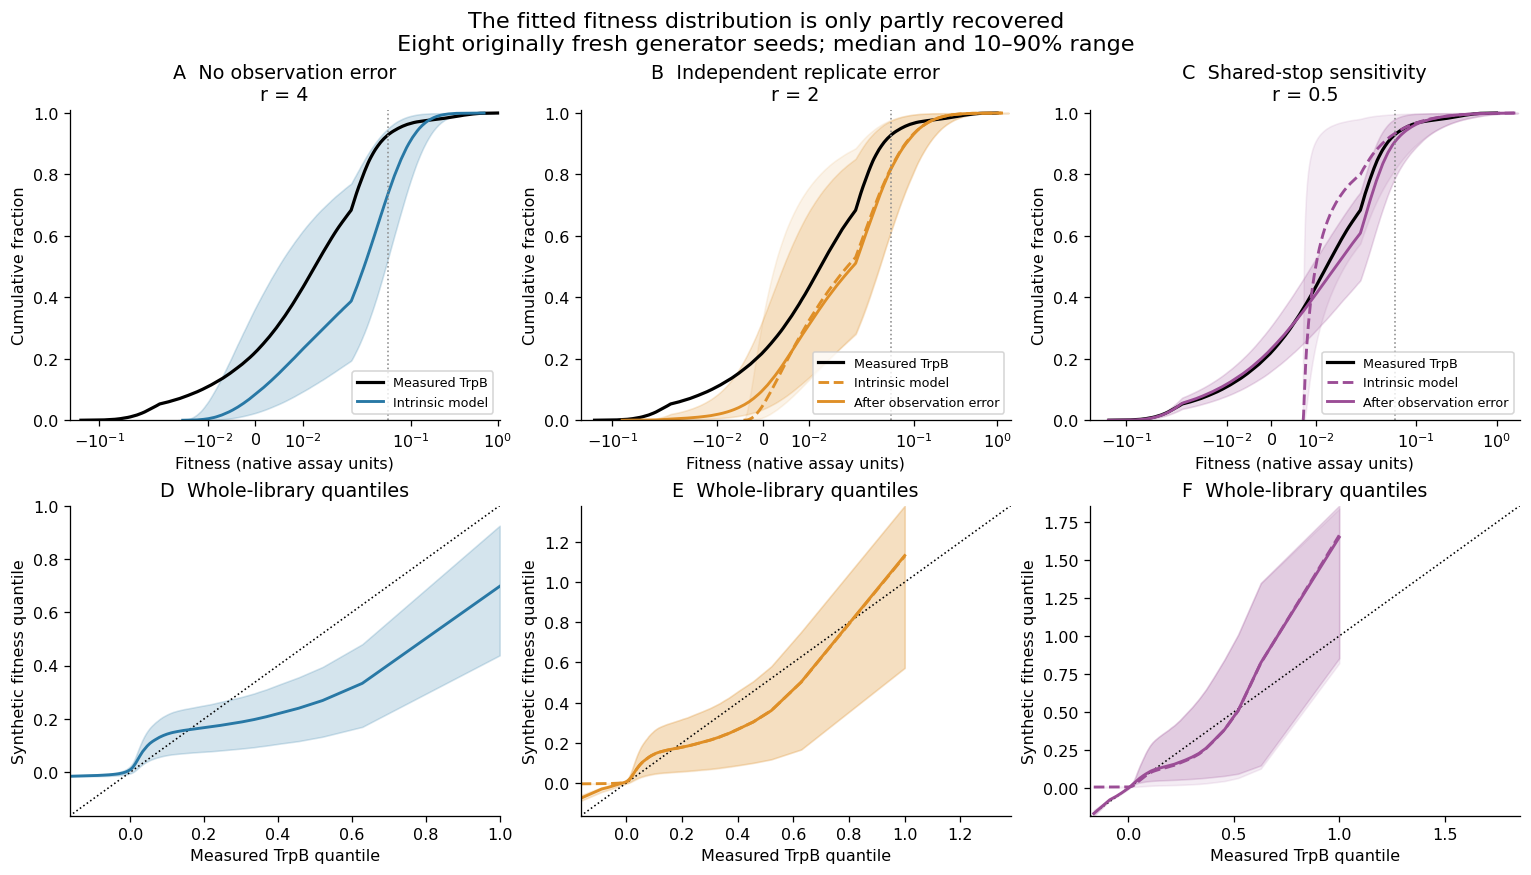

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13.2, 7.5), constrained_layout=True)
for column, mode in enumerate(MODES):
    color = MODE_COLORS[mode]
    setting = next(s for s in ctx.settings if s['observation'] == mode)
    ax, qq = axes[:, column]
    ax.plot(empirical_quantiles, probabilities, color='black', lw=2, label='Measured TrpB')
    layers = ['intrinsic'] if mode == 'none' else ['intrinsic', 'observed']
    qmax = max(1., float(qsummary[qsummary.observation.eq(mode)].q90.max()))
    qmin = min(float(empirical_values.min()), float(qsummary[qsummary.observation.eq(mode)].q10.min()))
    qq.plot([qmin, qmax], [qmin, qmax], color='black', lw=1, ls=':')
    for layer in layers:
        q = qsummary[qsummary.observation.eq(mode) & qsummary.layer.eq(layer)].sort_values('probability')
        line = '--' if layer == 'intrinsic' and mode != 'none' else '-'
        label = 'Intrinsic model' if layer == 'intrinsic' else 'After observation error'
        ax.fill_betweenx(q.probability, q.q10, q.q90, color=color, alpha=.10 if line == '--' else .20)
        ax.plot(q['median'], q.probability, color=color, ls=line, lw=1.8, label=label)
        qq.fill_between(empirical_quantiles, q.q10, q.q90, color=color, alpha=.10 if line == '--' else .20)
        qq.plot(empirical_quantiles, q['median'], color=color, ls=line, lw=1.8)
    ax.axvline(ctx.floor, color='0.55', ls=':', lw=1)
    ax.set_xscale('symlog', linthresh=.02)
    ax.set(xlabel='Fitness (native assay units)', ylabel='Cumulative fraction',
           title=f'{chr(65+column)}  {MODE_LABELS[mode]}\nr = {setting["ratio"]:g}', ylim=(0, 1.01))
    qq.set(xlabel='Measured TrpB quantile', ylabel='Synthetic fitness quantile',
           title=f'{chr(68+column)}  Whole-library quantiles', xlim=(qmin, qmax), ylim=(qmin, qmax))
    ax.legend(loc='lower right', fontsize=8)
fig.suptitle('The fitted fitness distribution is only partly recovered\nEight originally fresh generator seeds; median and 10–90% range', fontsize=14)
save_figure(fig, figures, '01_average_fitness_distribution')
plt.show()

## Confirmation-cube summaries

Local spread is the mean standard deviation within a 16-genotype cube.
Near-floor fraction counts values at or below the frozen native cutoff.
Diminishing returns is the median slope of a **fixed mutation** across its eight
genetic backgrounds: effect versus starting fitness, using the original
background-variance eligibility threshold (epsilon = 0.001 times the frozen
calibration scale). Negative slopes describe a fitness–effect relationship;
they do not identify a molecular mechanism.

Mutation magnitudes use all 32 undirected edges per cube once. Absolute values
avoid treating arbitrary binary allele orientation as biological direction.
These are two-allele local cubes, not the full amino-acid-substitution DFE.

In [5]:
primary = ctx.cubes[np.isclose(ctx.cubes.relative_resolution, .001)].copy()
metrics = ['sd_fitness', 'near_floor_fraction', 'slope_median']
empirical_cube = primary[primary.cohort.eq('empirical')].iloc[0]
local = primary[~primary.cohort.eq('empirical')]
local_long = local.melt(id_vars=['seed', 'cohort', 'observation', 'ratio', 'layer'],
                       value_vars=metrics, var_name='metric', value_name='value')
local_summaries = []
for cohort in ['fresh', 'reused', 'all']:
    data = local_long if cohort == 'all' else local_long[local_long.cohort.eq(cohort)]
    summary = quantile_summary(data, ['observation', 'ratio', 'layer', 'metric'])
    summary['cohort'] = cohort
    local_summaries.append(summary)
local_summary = pd.concat(local_summaries, ignore_index=True)
local_summary.to_csv(tables / 'average_local_summary.csv', index=False)
local_long.to_csv(tables / 'average_local_by_seed.csv', index=False)
pd.DataFrame([dict(metric=m, value=float(empirical_cube[m])) for m in metrics]).to_csv(
    tables / 'average_empirical_local.csv', index=False)
effect_prob = np.linspace(0, 1, 101)
empirical_effect_quantiles = np.quantile(np.abs(fixed_direction_effects(ctx.empirical_cubes)), effect_prob)
effect_rows = []
for row in ctx.audit.itertuples(index=False):
    with np.load(ctx.output / 'cube_values' / f'TrpB_{row.seed}.npz') as saved:
        for setting in ctx.settings:
            mode, ratio = setting['observation'], setting['ratio']
            for layer in (['intrinsic'] if mode == 'none' else ['intrinsic', 'observed']):
                y = saved[f'{mode}_{layer}_r{ratio:g}']
                q = np.quantile(np.abs(fixed_direction_effects(y)), effect_prob)
                effect_rows.extend(dict(seed=int(row.seed), cohort=row.cohort, observation=mode,
                    ratio=float(ratio), layer=layer, probability=float(p), value=float(v))
                    for p, v in zip(effect_prob, q))
effect_quantiles = pd.DataFrame(effect_rows)
effect_quantiles.to_csv(tables / 'average_mutation_effect_quantiles.csv.gz', index=False)
pd.DataFrame({'probability': effect_prob, 'absolute_effect': empirical_effect_quantiles}).to_csv(
    tables / 'average_empirical_mutation_effect_quantiles.csv', index=False)
effect_summary = quantile_summary(effect_quantiles[effect_quantiles.cohort.eq('fresh')],
                                 ['observation', 'ratio', 'layer', 'probability'])
effect_summary.to_csv(tables / 'average_fresh_mutation_effect_summary.csv', index=False)

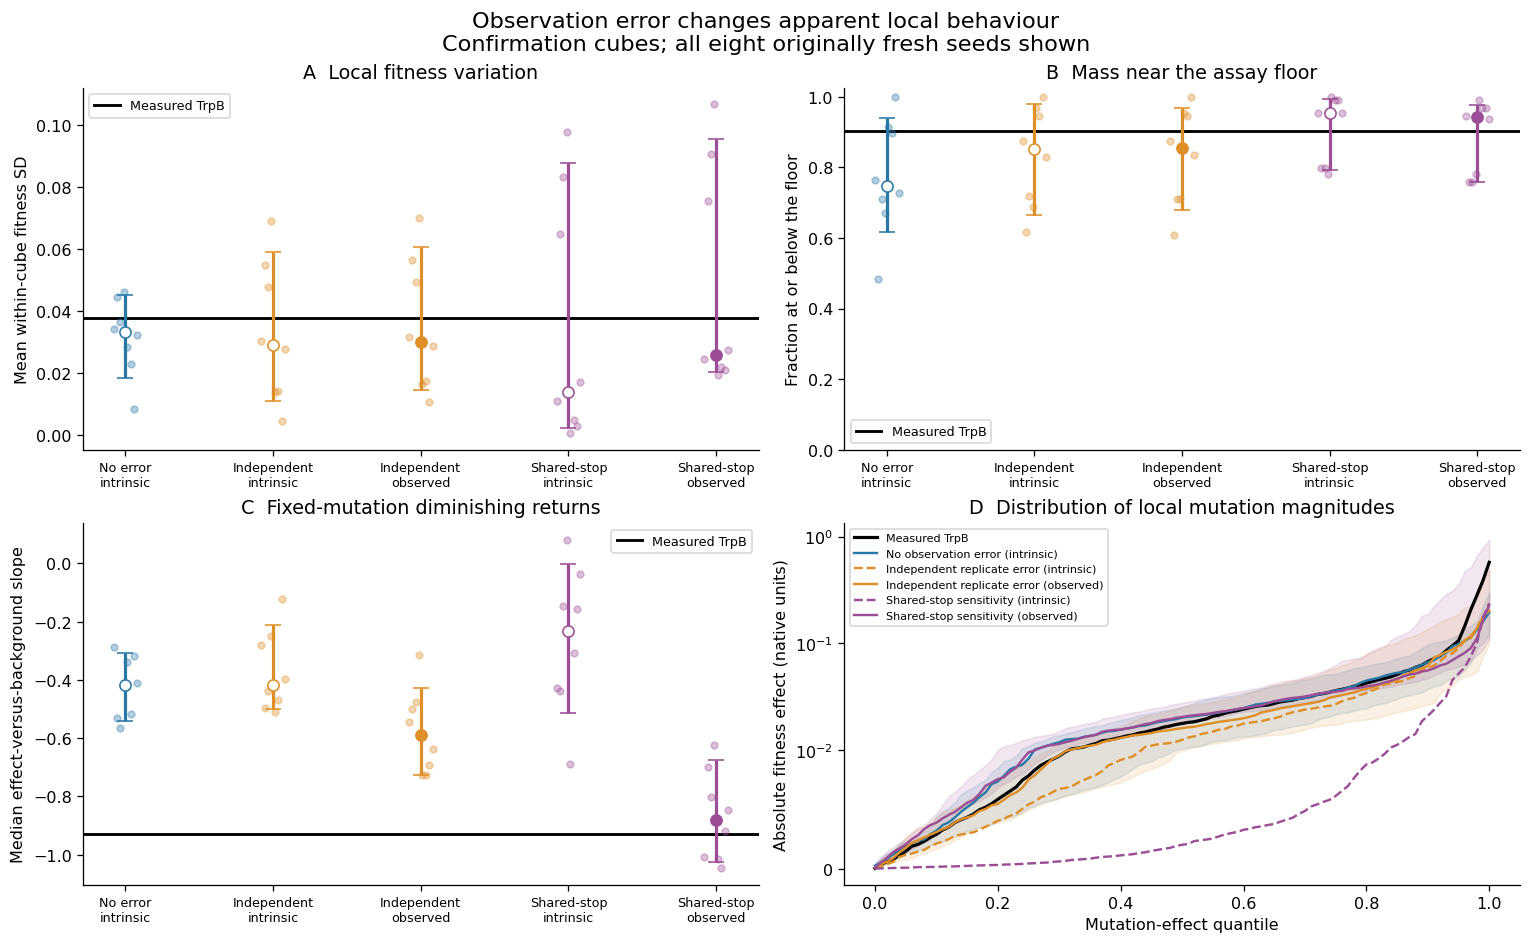

In [6]:
groups = [('none', 'intrinsic'), ('independent_difference', 'intrinsic'),
          ('independent_difference', 'observed'), ('shared_stop_sensitivity', 'intrinsic'),
          ('shared_stop_sensitivity', 'observed')]
group_labels = ['No error\nintrinsic', 'Independent\nintrinsic', 'Independent\nobserved',
                'Shared-stop\nintrinsic', 'Shared-stop\nobserved']
titles = ['A  Local fitness variation', 'B  Mass near the assay floor',
          'C  Fixed-mutation diminishing returns']
ylabels = ['Mean within-cube fitness SD', 'Fraction at or below the floor',
           'Median effect-versus-background slope']
fig, axes = plt.subplots(2, 2, figsize=(13.2, 8.1), constrained_layout=True)
fresh_local = local_summary[local_summary.cohort.eq('fresh')]
for ax, metric, title, ylabel in zip(axes.ravel()[:3], metrics, titles, ylabels):
    ax.axhline(empirical_cube[metric], color='black', lw=1.8, label='Measured TrpB')
    for i, (mode, layer) in enumerate(groups):
        v = fresh_local[fresh_local.observation.eq(mode) & fresh_local.layer.eq(layer)
                        & fresh_local.metric.eq(metric)].iloc[0]
        y = local[local.cohort.eq('fresh') & local.observation.eq(mode) & local.layer.eq(layer)][metric].to_numpy()
        color = MODE_COLORS[mode]
        ax.scatter(i + np.linspace(-.08, .08, len(y)), y, s=18, alpha=.35, color=color, zorder=3)
        ax.errorbar(i, v['median'], yerr=[[v['median']-v.q10], [v.q90-v['median']]],
                    fmt='o', capsize=5, color=color, ms=7, lw=2,
                    mfc='white' if layer == 'intrinsic' else color, zorder=4)
    ax.set_xticks(range(len(groups)), group_labels, fontsize=8)
    ax.set(title=title, ylabel=ylabel)
    if metric == 'near_floor_fraction': ax.set_ylim(0, 1.025)
    ax.legend(loc='best', fontsize=8)
ax = axes[1, 1]
ax.plot(effect_prob, empirical_effect_quantiles, color='black', lw=2, label='Measured TrpB')
for mode, layer in groups:
    q = effect_summary[effect_summary.observation.eq(mode) & effect_summary.layer.eq(layer)].sort_values('probability')
    line = '--' if layer == 'intrinsic' and mode != 'none' else '-'
    ax.plot(q.probability, q['median'], color=MODE_COLORS[mode], ls=line, lw=1.5,
            label=f'{MODE_LABELS[mode]} ({layer})')
    if layer == 'observed' or mode == 'none':
        ax.fill_between(q.probability, q.q10, q.q90, color=MODE_COLORS[mode], alpha=.13)
ax.set_yscale('symlog', linthresh=.01)
ax.set(xlabel='Mutation-effect quantile', ylabel='Absolute fitness effect (native units)',
       title='D  Distribution of local mutation magnitudes')
ax.legend(fontsize=7, loc='upper left')
fig.suptitle('Observation error changes apparent local behaviour\nConfirmation cubes; all eight originally fresh seeds shown', fontsize=14)
save_figure(fig, figures, '02_average_local_behaviour')
plt.show()

## Interpretation

The broad low-fitness bulk and nonzero local variation are present, but native
distribution and local spread retain mismatches. Shared-stop observations make
diminishing returns much closer to TrpB than that fit's intrinsic map. Error
therefore contributes to agreement and cannot be interpreted as recovered
biological interactions. Marginal fitness recovery alone is insufficient.

Historical warm starts won all three joint Optuna searches. These selected
ensembles do not establish convergence, TrpB equivalence or genotype-level
correctness. Architecture and difficulty notebooks assess complementary
unfitted summaries with the same observation/seed distinctions.

In [7]:
display_columns = ['observation', 'layer', 'metric', 'median', 'q10', 'q90']
print('Empirical full-library distribution:', empirical_distribution)
print('\nFresh-seed full-library summaries:')
print(distribution_summary[distribution_summary.cohort.eq('fresh') &
      distribution_summary.metric.isin(['mean', 'sd', 'near_floor_fraction', 'q99'])][display_columns].to_string(index=False))
print('\nFresh-seed confirmation-cube summaries:')
print(fresh_local[display_columns].to_string(index=False))

Empirical full-library distribution: {'n': 159129, 'mean': 0.02114863848850932, 'sd': 0.05997840164804073, 'near_floor_fraction': 0.9294785991239811, 'minimum': -0.164070661, 'median': 0.01242355, 'q99': 0.3500446586000003, 'maximum': 1.0}

Fresh-seed full-library summaries:
            observation     layer              metric   median      q10      q90
                   none intrinsic                mean 0.040201 0.011054 0.067688
 independent_difference intrinsic                mean 0.033484 0.007549 0.065140
 independent_difference  observed                mean 0.033487 0.007528 0.065114
shared_stop_sensitivity intrinsic                mean 0.022743 0.008651 0.049932
shared_stop_sensitivity  observed                mean 0.022736 0.008694 0.049889
                   none intrinsic                  sd 0.043742 0.022550 0.063373
 independent_difference intrinsic                  sd 0.049170 0.016665 0.082575
 independent_difference  observed                  sd 0.049765 0.019234 0.08